<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/07_cLab_TcEstudiante.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Laboratorio — Determinación de la temperatura crítica del modelo de Ising 2D con redes neuronales de *scikit-learn*

**Maestría en Computación Científica · Módulo de Redes Neuronales · Modelo de Ising 2D**

En este laboratorio vas a **entrenar una red neuronal clasificadora con `scikit-learn`** y a
usarla como un *termómetro* para localizar la **temperatura crítica** $T_c$ de la transición
de fase ferromagnética del modelo de Ising en 2D.



## Objetivos de aprendizaje

Al terminar este laboratorio serás capaz de:

1. Entrenar un clasificador de red neuronal con `sklearn.neural_network.MLPClassifier`,
   identificando el papel de cada hiperparámetro.
2. **Contrastar la API de `scikit-learn`
3. Usar un clasificador entrenado **lejos** de la transición para estimar la fase
   (ordenada / desordenada) a temperaturas **cercanas** a $T_c$.
4. Estimar $T_c$ a partir del cruce $\langle P(y{=}1\mid X)\rangle = 0.5$, cuantificar su
   incertidumbre entre realizaciones y compararla con el valor exacto de Onsager.

## 1. Física: transición de fase del modelo de Ising 2D

El modelo de Ising 2D en una red $L\times L$ con acoplamiento ferromagnético $J>0$ tiene energía

$$E(\{s\}) = -J \sum_{\langle i,j\rangle} s_i\, s_j, \qquad s_i \in \{-1, +1\},$$

donde la suma es sobre pares de primeros vecinos. En unidades $J = k_B = 1$, el sistema infinito
presenta una transición de fase de segundo orden a la **temperatura crítica de Onsager**

$$T_c = \frac{2}{\ln\!\left(1+\sqrt{2}\right)} \approx 2.269.$$

- $T < T_c$: **fase ordenada** (ferromagnética), magnetización por sitio $|m|$ grande.
- $T > T_c$: **fase desordenada** (paramagnética), $|m|\approx 0$.

**Idea del laboratorio** (Carrasquilla & Melko, *Nature Physics* **13**, 431 (2017)): un
clasificador entrenado solo con configuraciones *claramente* ordenadas ($y=0$) y *claramente*
desordenadas ($y=1$) aprende una frontera de decisión que, evaluada en configuraciones cercanas
a $T_c$, se comporta como un **parámetro de orden efectivo**. La temperatura donde
$\langle P(y{=}1\mid X)\rangle = 0.5$ estima $T_c$.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPClassifier

RNG = 42
np.random.seed(RNG)

## 3. Datos: configuraciones lejos de $T_c$

`ising_dataset.npz` contiene configuraciones de espines de una red $16\times 16$ con frontera
periódica, generadas por Monte Carlo (Metrópolis). Campos:

| Campo | Forma | Significado |
|---|---|---|
| `X` | `(1600, 16, 16)` | Configuraciones de espines $s_i \in \{-1,+1\}$ |
| `y` | `(1600,)` | Etiqueta de fase: `0` = ordenada ($T$ baja), `1` = desordenada ($T$ alta) |
| `T` | `(1600,)` | Temperatura de cada configuración |
| `m` | `(1600,)` | Magnetización por sitio $|m|$ |
| `realizacion` | `(1600,)` | Índice de cadena Monte Carlo independiente (`0..3`) |
| `Tc`, `L`, `frontera` | escalares | Metadatos ($T_c$ exacto, tamaño, tipo de frontera) |

Las temperaturas de entrenamiento **evitan** la región crítica: hay un hueco entre
$T=1.9$ y $T=2.6$.

In [27]:
datos = np.load("ising_dataset.npz", allow_pickle=False)
X = datos["X"]
y = datos["y"]
T = datos["T"]
m = datos["m"]
realizacion = datos["realizacion"]

Tc_exacto = float(datos["Tc"])
L = int(datos["L"])

print("X:", X.shape, X.dtype)
print("y:", y.shape, "->", np.unique(y, return_counts=True))
print("realizaciones:", np.unique(realizacion))
print("Tc exacto (Onsager):", Tc_exacto)


def cruce_05(temps, probs):
    temps, probs = np.asarray(temps), np.asarray(probs)
    for i in range(len(temps) - 1):
        if (probs[i] - 0.5) * (probs[i + 1] - 0.5) <= 0 and probs[i + 1] != probs[i]:
            return (temps[i] + (0.5 - probs[i]) *
                    (temps[i + 1] - temps[i]) / (probs[i + 1] - probs[i]))
    return np.nan

X: (1600, 16, 16) int8
y: (1600,) -> (array([0, 1], dtype=int8), array([800, 800]))
realizaciones: [0 1 2 3]
Tc exacto (Onsager): 2.269185314213022


### Ejercicio 1 — Exploración

Responde con código y en una celda de texto:

1. ¿Qué temperaturas tienen etiqueta `y = 0` y cuáles `y = 1`? ¿Dónde está el "hueco"?
2. ¿Está balanceado el problema (cuántas configuraciones por clase)?
3. Grafica el histograma de $|m|$ separando por clase. ¿Se separan bien las dos fases?

In [28]:
#1 identificar las temperaturas presentes en T, identificar cuales son altas y bajas

temp = {} # dicionario para almacenar las temperaturas (no repetidas) y su clasificación (alta o baja) (solo para clasificar)

# contadores para identificar cuantas configuraciones por clase
lowt = 0
hight = 0

# listas para almacenar los valores de temperatura alta y baja
lowt_values = []
hight_values = []

for i in range(len(T)):
    if y[i] == 0:
        temp[float(T[i])] = "baja Temp"
        lowt += 1
        lowt_values.append(float(T[i]))
    else:
        temp[float(T[i])] = "Alta Temp"
        hight += 1
        hight_values.append(float(T[i]))

print("Valores de temperaturas")
for i, clasficacion in temp.items():
    print(i,":", clasficacion)
print("=====================================================")
print("Cantidad de configuraciones de baja temperatura:", lowt)
print("Cantidad de configuraciones de alta temperatura:", hight)

Valores de temperaturas
3.5 : Alta Temp
3.275 : Alta Temp
3.05 : Alta Temp
2.825 : Alta Temp
2.6 : Alta Temp
1.9 : baja Temp
1.7249999999999999 : baja Temp
1.5499999999999998 : baja Temp
1.375 : baja Temp
1.2 : baja Temp
Cantidad de configuraciones de baja temperatura: 800
Cantidad de configuraciones de alta temperatura: 800


### 1
Las temperaturas correspondientes a la fase ordenada (y =0) son: 1.2, 1.375, 1.55, 1.725, 1.9.
Las temperaturas correspondientes a la fase desordenada (y=1) son: 1.9, 2.6, 2.825, 3.05, 3.275, 3.5

El hueco crítico de temperaturas está entre 1.9 y 2.6

### 2

El dataset está perfectamente balanceado con 800 instancias por clase (50% / 50%).

In [29]:
# encontar donde cambia de 1 a 0
for i in range(len(y)-1):
    if y[i] == 1 and y[i+1] == 0:
        print("Cambio de 1 a 0 en el índice:", i)

# los datos de temperatura no están comletamente ordenados

Cambio de 1 a 0 en el índice: 199
Cambio de 1 a 0 en el índice: 599
Cambio de 1 a 0 en el índice: 999
Cambio de 1 a 0 en el índice: 1399


podemos organizar los valores de alta y baja temperatura en forma descendente. Aquí también es evidente donde está el hueco en el rango de temperaturas.

In [30]:

sorted_hight_values = np.sort(hight_values)[::-1]  # Ordenar de mayor a menor los valores de alta temperatura
sorted_lowt_values = np.sort(lowt_values)[::-1]  # Ordenar de menor a mayor los valores de baja temperatura

print("valor mas bajo de alta temperatura:", sorted_hight_values[-1])  # Imprimir el valor más bajo de alta temperatura
print("valor mas alto de baja temperatura:", sorted_lowt_values[0])  # Imprimir el valor más alto de baja temperatura

sorted_temp_values = np.sort(T)[::-1]  # Ordenar todas las temperaturas presentes en el diccionario temp
sorted_temp_values


valor mas bajo de alta temperatura: 2.6
valor mas alto de baja temperatura: 1.9


array([3.5, 3.5, 3.5, ..., 1.2, 1.2, 1.2], shape=(1600,))

### 3. Histograma de |m| separado por clase


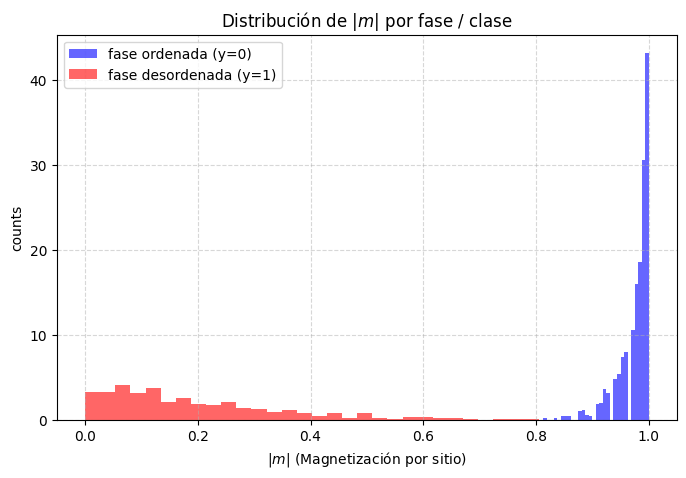

In [31]:

# 3. Histograma de |m| separado por clase
plt.figure(figsize=(8, 5))
plt.hist(
    np.abs(m[y == 0]),
    bins=30,
    alpha=0.6,
    label="fase ordenada (y=0)",
    color="blue",
    density=True,
)
plt.hist(
    np.abs(m[y == 1]),
    bins=30,
    alpha=0.6,
    label="fase desordenada (y=1)",
    color="red",
    density=True,
)

plt.xlabel(r"$|m|$ (Magnetización por sitio)")
plt.ylabel("counts")
plt.title("Distribución de $|m|$ por fase / clase")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

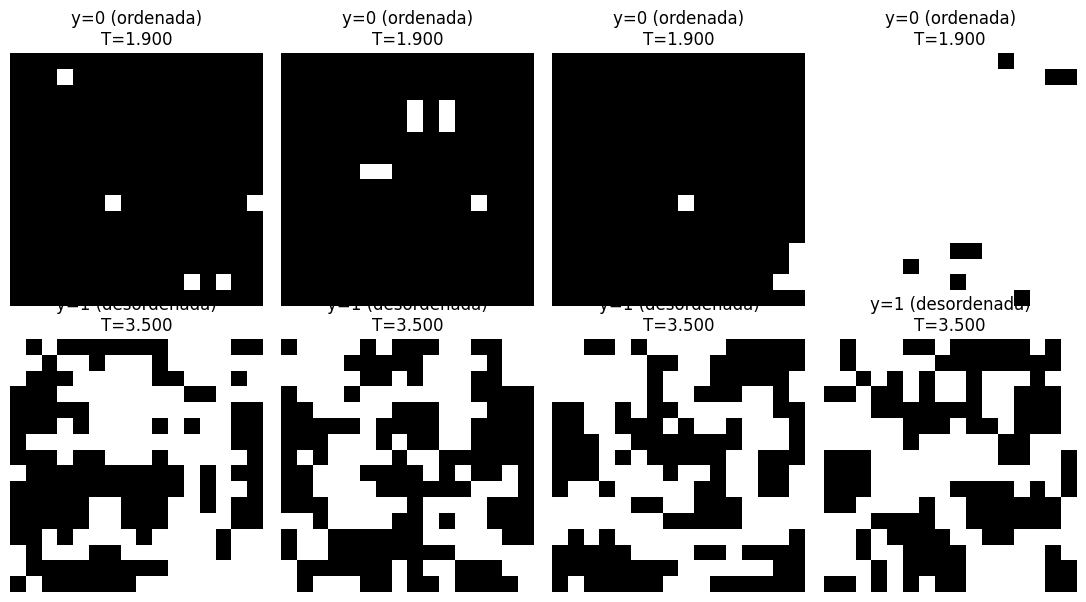

In [32]:
# Configuraciones típicas a T baja y T alta
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for row, (cls, titulo) in enumerate([(0, "ordenada"), (1, "desordenada")]):
    idx = np.where(y == cls)[0][:4]
    for k, i in enumerate(idx):
        axes[row, k].imshow(X[i], cmap="gray", vmin=-1, vmax=1)
        axes[row, k].set_title(f"y={cls} ({titulo})\nT={T[i]:.3f}")
        axes[row, k].axis("off")
plt.tight_layout()
plt.show()

## 4. Partición de los datos: por **realización**

Las configuraciones de una misma cadena Monte Carlo (`realizacion`) están **correlacionadas**
temporalmente. Si mezcláramos al azar, configuraciones casi idénticas caerían en *train* y en
*test* a la vez → fuga de información y métricas infladas.

Partimos por realización:

- **Entrenamiento:** realizaciones `0` y `1`
- **Validación:** realización `2`
- **Prueba:** realización `3`

Además aplanamos cada configuración $16\times16 \to 256$ porque `MLPClassifier` espera
vectores de características.

### Ejercicio 2 — Construir los conjuntos

Completa las máscaras y los arreglos aplanados. Deberías obtener
`X_train (800, 256)`, `X_val (400, 256)` y `X_test (400, 256)`.

In [33]:
# --- Ejercicio 2  ---
mask_train = np.isin(realizacion, [0, 1])
mask_val   = realizacion == 2
mask_test  = realizacion == 3

def aplanar(A):
    return A.reshape(A.shape[0], L * L)

X_train, y_train, T_train = aplanar(X[mask_train]), y[mask_train], T[mask_train]
X_val,   y_val,   T_val   = aplanar(X[mask_val]),   y[mask_val],   T[mask_val]
X_test,  y_test,  T_test  = aplanar(X[mask_test]),  y[mask_test],  T[mask_test]

for nombre, Xs, ys in [("train", X_train, y_train),
                       ("val",   X_val,   y_val),
                       ("test",  X_test,  y_test)]:
    print(f"{nombre:5s}  X={Xs.shape}  y={ys.shape}  clases={np.bincount(ys)}")

train  X=(800, 256)  y=(800,)  clases=[400 400]
val    X=(400, 256)  y=(400,)  clases=[200 200]
test   X=(400, 256)  y=(400,)  clases=[200 200]


## 5. Entrenar el `MLPClassifier`

| Argumento | Valor | Qué controla |
|---|---|---|
| `hidden_layer_sizes=(16, 8, 4)` | 3 capas ocultas | Arquitectura: 256 → 16 → 8 → 4 → 2 |
| `activation="relu"` | ReLU | No linealidad de las capas ocultas |
| `solver="adam"` | Adam | Optimizador basado en gradiente estocástico |
| `learning_rate_init=0.001` | 0.001 | Tamaño de paso inicial |
| `max_iter=1000` | 1000 | Máximo de épocas (puede parar antes por tolerancia) |
| `random_state=42` | 42 | Reproducibilidad (init de pesos y *shuffling*) |

> La capa de salida (2 neuronas, *softmax*) y la pérdida (*log-loss*) las añade `scikit-learn`
> automáticamente al ver que `y` tiene dos clases enteras. En `NN_Cero.ipynb` esto era la
> `sigmoide` final + `cost_Function`; en PyTorch era `nn.Linear(..., 1)` + `BCEWithLogitsLoss`.

### Ejercicio 3 — Instanciar, entrenar y evaluar

1. Crea el modelo con los hiperparámetros de la tabla y ajústalo con `X_train, y_train`.
2. Reporta *accuracy* en train / val / test con `.score(...)`.
3. Grafica `model.loss_curve_` (la pérdida por época que `scikit-learn` guarda).

iteraciones: 675   log-loss final: 0.0453
accuracy train: 1.0000
accuracy val  : 0.9850
accuracy test : 0.9875


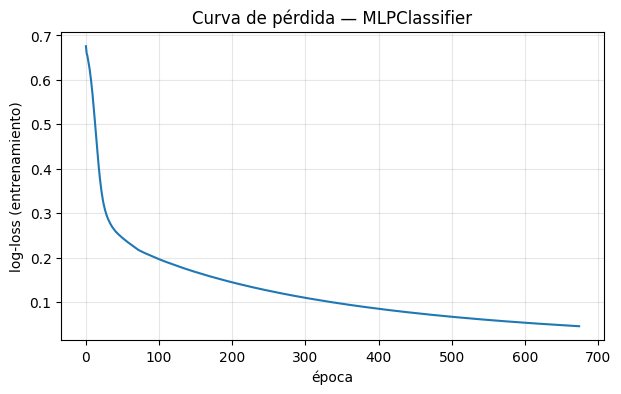

In [34]:
# --- Ejercicio 3  ---
model = MLPClassifier(
    hidden_layer_sizes=(16, 8, 4),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=RNG,
)
model.fit(X_train, y_train)

acc = {
    "train": model.score(X_train, y_train),
    "val":   model.score(X_val,   y_val),
    "test":  model.score(X_test,  y_test),
}
print(f"iteraciones: {model.n_iter_}   log-loss final: {model.loss_:.4f}")
for k, v in acc.items():
    print(f"accuracy {k:5s}: {v:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(model.loss_curve_)
plt.xlabel("época")
plt.ylabel("log-loss (entrenamiento)")
plt.title("Curva de pérdida — MLPClassifier")
plt.grid(alpha=0.3)
plt.show()

### Reflexión (sección 5)

- El *accuracy* de entrenamiento suele ser `1.0000`. ¿Es esto sobreajuste preocupante, dado que
  train / val / test dan valores parecidos? ¿Por qué este problema es "fácil" **lejos** de $T_c$?


El accuracy corresponde simpelemente a la fracción de ejemplos que el clasificador etiqueta correctamente. En nuestro caso, el accuracy de validación y test es muy bueno, por lo que aún si el accuracy de entrenamiento es 1.0 (el modelo clasifica todos los datos de entrenamiento de forma correcta), no necesariamente se tiene un caso de sobre ajuste. El modelo es capaz de clasificar muy bien los datos nuevos que no se usaron durante su entrenamiento, es decir, los datos de  validación y de test.

- lejos de la temperatura crítica, las dos fases tienen características muy diferentes. Las configuraciones tienen señales evidentes que le permiten al clasificador tomar decisiones sin mayor dificultad.  


- ¿Qué esperas que ocurra con las probabilidades del modelo **cerca** de $T_c$, donde no vio datos?

En este caso, le estámos preguntando al modelo valores de temperatura y configuraciones que no vio durante su entrenamiento. Por ejemplo en el caso ordenado (bajas temperaturas), esperamos probabilidades muy claras, $P(ordenado) \approx 1$, $P(desordenado) \approx 0$, y viceversa, con cambios pocos significativos cerca a los valores extremos de temperatura.


 Sin embargo, cerca de $T_c$, los resultados ahora serán más ambiguos y no tan marcados. El modelo debería predecir probabilidades cercanas a $0.5$. Así, aunque el clasificador no haya sido entrenado directamente para encontrar $T_c$, las regiones donde la probabilidad cambie rápidamente y sea cercana a $0.5$, puede ser un indicio de la región donde se encuentra $T_c$.

## 6. El clasificador como termómetro

Para una configuración $X$, `model.predict_proba(X)[:, 1]` es $P(y{=}1\mid X)$: la "confianza"
del modelo en que la configuración pertenece a la **fase desordenada**.

Promediando sobre muchas configuraciones a temperatura fija $T$ obtenemos una curva
$\langle P(y{=}1\mid X)\rangle(T)$ que va de $\approx 0$ (ordenado) a $\approx 1$ (desordenado).
Definimos la estimación de $T_c$ como la temperatura del **cruce por 0.5**.

## 7. Datos de barrido fino alrededor de $T_c$

`temperatura_critica.npz` contiene **6200** configuraciones $16\times16$ en **31 temperaturas**
entre 1.6 y 3.2 (más densas cerca de $T_c$), con 4 realizaciones. **No trae etiquetas de
entrenamiento:** solo `y_ref`, una etiqueta obtenida aplicando el $T_c$ exacto, que usaremos
**únicamente para verificar** (usarla para entrenar sería hacer trampa).

In [35]:
datos_tc = np.load("temperatura_critica.npz", allow_pickle=False)
X_tc = datos_tc["X"].reshape(datos_tc["X"].shape[0], L * L)
T_tc = datos_tc["T"]
realizacion_tc = datos_tc["realizacion"]
y_ref_tc = datos_tc["y_ref"]

print("X_tc:", X_tc.shape)
print("temperaturas:", np.unique(T_tc))

# Probabilidad de la clase "desordenada" (y = 1)
idx1 = list(model.classes_).index(1)
p1_tc = model.predict_proba(X_tc)[:, idx1]

# Chequeo con y_ref (NO usar para entrenar)
pred_tc = (p1_tc >= 0.5).astype(int)
print("accuracy vs y_ref (solo verificacion):",
      round((pred_tc == y_ref_tc).mean(), 4))

X_tc: (6200, 256)
temperaturas: [1.6   1.7   1.8   1.9   2.    2.05  2.075 2.1   2.125 2.15  2.175 2.2
 2.225 2.25  2.275 2.3   2.325 2.35  2.375 2.4   2.425 2.45  2.475 2.5
 2.6   2.7   2.8   2.9   3.    3.1   3.2  ]
accuracy vs y_ref (solo verificacion): 0.8247


### Ejercicio 4 — Curva $\langle P\rangle$ vs $T$

Construye un `DataFrame` con columnas `T, realizacion, prob` y agrégalo por
`(realizacion, T)` para obtener la media y la desviación de `prob`. Grafica una curva por
realización y marca la línea $P = 0.5$.

In [36]:
# --- Ejercicio 4 ---
df = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "prob": p1_tc})

resumen = (df.groupby(["realizacion", "T"])
             .agg(prob_media=("prob", "mean"),
                  prob_std=("prob", "std"),
                  N=("prob", "size"))
             .reset_index())

print(resumen.head(10))

   realizacion      T  prob_media  prob_std   N
0            0  1.600    0.086512  0.000394  50
1            0  1.700    0.099844  0.073550  50
2            0  1.800    0.118671  0.142166  50
3            0  1.900    0.096877  0.044426  50
4            0  2.000    0.194088  0.231677  50
5            0  2.050    0.312571  0.323194  50
6            0  2.075    0.292059  0.330682  50
7            0  2.100    0.247549  0.259990  50
8            0  2.125    0.404434  0.329513  50
9            0  2.150    0.345801  0.344387  50


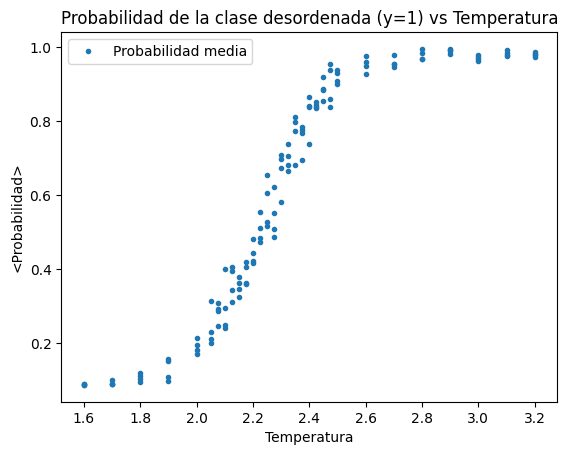

In [37]:
# Realizar el grafico
plt.title("Probabilidad de la clase desordenada (y=1) vs Temperatura")
plt.xlabel("Temperatura")
plt.ylabel("<Probabilidad>")
plt.plot(resumen["T"], resumen["prob_media"], 'o', markersize=3,label="Probabilidad media")
plt.legend()
plt.show()

### Ejercicio 5 — Estimar $T_c$ por interpolación

Para cada realización, encuentra el primer par de temperaturas consecutivas donde
$\langle P\rangle$ cruza 0.5 e interpola linealmente:

$$T_c \approx T_i + (0.5 - P_i)\,\frac{T_{i+1}-T_i}{P_{i+1}-P_i}.$$

Luego promedia entre realizaciones y reporta la media, la desviación estándar y el error
estándar de la media (SEM).

In [38]:
Tc_por_realizacion = []
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    Tc_r = cruce_05(d["T"].to_numpy(), d["prob_media"].to_numpy())
    Tc_por_realizacion.append(Tc_r)
    print(f"realización {r}:  Tc = {Tc_r:.4f}")

Tc_por_realizacion = np.array(Tc_por_realizacion)
Tc_est = np.nanmean(Tc_por_realizacion)
Tc_std = np.nanstd(Tc_por_realizacion, ddof=1)
Tc_sem = Tc_std / np.sqrt(np.sum(~np.isnan(Tc_por_realizacion)))

print("\n" + "-" * 44)
print(f"Tc estimado    = {Tc_est:.4f} +/- {Tc_sem:.4f} (SEM)")
print(f"Tc Onsager     = {Tc_exacto:.4f}")
print(f"error relativo = {100 * abs(Tc_est - Tc_exacto) / Tc_exacto:.2f} %")

realización 0:  Tc = 2.2403
realización 1:  Tc = 2.2204
realización 2:  Tc = 2.2149
realización 3:  Tc = 2.2280

--------------------------------------------
Tc estimado    = 2.2259 +/- 0.0055 (SEM)
Tc Onsager     = 2.2692
error relativo = 1.91 %


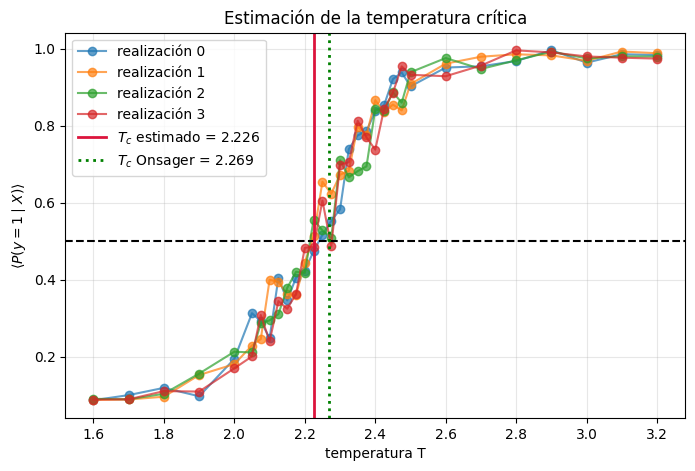

In [39]:
plt.figure(figsize=(8, 5))
for r in np.unique(realizacion_tc):
    d = resumen[resumen.realizacion == r].sort_values("T")
    plt.plot(d["T"], d["prob_media"], "o-", alpha=0.7, label=f"realización {r}")
plt.axhline(0.5, ls="--", color="k")
plt.axvline(Tc_est, ls="-", color="crimson", lw=2,
            label=fr"$T_c$ estimado = {Tc_est:.3f}")
plt.axvline(Tc_exacto, ls=":", color="green", lw=2,
            label=fr"$T_c$ Onsager = {Tc_exacto:.3f}")
plt.xlabel("temperatura T")
plt.ylabel(r"$\langle P(y=1\mid X)\rangle$")
plt.title("Estimación de la temperatura crítica")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8.1:  Análisis crítico

Responde en celdas de texto, con evidencia (números o gráficas de tu notebook):

1. **Sesgo del estimador.** El $T_c$ estimado suele quedar *por debajo* de Onsager
   ($\approx 2.23$ vs $2.269$). Menciona al menos dos causas: tamaño finito $L=16$, definición
   de la etiqueta `y`, rango de temperaturas de entrenamiento, uso del umbral fijo 0.5.

- El resultado de Onsager corresponde al límite termodinámco de una red infinita $L \to \infty$. En nuestro sistema de $16 \times 16$, los efectos de tamaño finito afectan las propiedas de transición al rededor del valor teórico de $T_c$.

- Así mismo, tenemos un gran hueco en los datos de temperatura, entre 1.9 y 2.6. Nuestro modelo está aprendiendo que pasa en las regiones de alta y baja temperatura, donde las fases están más o menos bien determinadas. Sin embargo, al preguntarle por la región al rededor de $T_c$, el clasificador tiene que hacer un tipo de extrapolación.

- Finalmente, el uso del umbral fijo de $0.5$ es razonable para nuestra clasficación binaria, sin embargo, no es algo que se deduzca físicamente.


## 8.2. Arquitectura:  
Repite el pipeline con `hidden_layer_sizes=(64,)` y con `(32, 16, 8)`.
   ¿Cambia $T_c$? ¿Cambia la *pendiente* de la curva en la transición?

### Modelo de entrenamiento
Convertimos todo el código en un solo bloque de función para usarlo más fácil. Convenientemente, la definimos como función de las variables ocultas y el estado random

In [40]:
# Pendiente de la curva en el cruce por 0.5 (mismo intervalo que usa cruce_05)
def pendiente_05(temps, probs):
    temps, probs = np.asarray(temps), np.asarray(probs)
    for i in range(len(temps) - 1):
        if (probs[i] - 0.5) * (probs[i + 1] - 0.5) <= 0 and probs[i + 1] != probs[i]:
            return (probs[i + 1] - probs[i]) / (temps[i + 1] - temps[i])
    return np.nan

# Estima Tc con cualquier modelo que tenga predict_proba (usa X_tc, T_tc, realizacion_tc)
def estimar_Tc(modelo, usar_fraccion=False):
    idx1 = list(modelo.classes_).index(1)
    p1 = modelo.predict_proba(X_tc)[:, idx1]
    valor = (p1 >= 0.5).astype(float) if usar_fraccion else p1   # fracción pred=1, o prob. media
    df = pd.DataFrame({"T": T_tc, "realizacion": realizacion_tc, "valor": valor})
    resumen = df.groupby(["realizacion", "T"], as_index=False)["valor"].mean()
    Tcs, pends = [], []
    for r in np.unique(realizacion_tc):
        d = resumen[resumen.realizacion == r].sort_values("T")
        Tcs.append(cruce_05(d["T"].to_numpy(), d["valor"].to_numpy()))
        pends.append(pendiente_05(d["T"].to_numpy(), d["valor"].to_numpy()))
    Tcs = np.array(Tcs)
    return {"Tc_est": np.nanmean(Tcs),
            "Tc_std": np.nanstd(Tcs, ddof=1),          # dispersión entre realizaciones
            "Tc_por_realizacion": Tcs,
            "pendiente": np.nanmean(pends),
            "resumen": resumen}

def entrenar_mlp(hidden_layer_sizes, random_state=RNG, verbose=True, plots=False):
    modelo = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes, activation="relu", solver="adam",
        learning_rate_init=0.001, max_iter=1000, random_state=random_state)
    modelo.fit(X_train, y_train)

    acc = {"train": modelo.score(X_train, y_train),
           "val":   modelo.score(X_val,   y_val),
           "test":  modelo.score(X_test,  y_test)}
    info = estimar_Tc(modelo)

    if verbose:
        print(f"Arquitectura: {hidden_layer_sizes} | semilla: {random_state}")
        print(f"iteraciones: {modelo.n_iter_}   log-loss final: {modelo.loss_:.4f}")
        print("accuracy:", {k: round(v, 4) for k, v in acc.items()})
        print(f"Tc = {info['Tc_est']:.4f} (std entre realizaciones = {info['Tc_std']:.4f}) | "
              f"Onsager = {Tc_exacto:.4f} | error relativo = {100*abs(info['Tc_est']-Tc_exacto)/Tc_exacto:.2f} %")
        print(f"pendiente en el cruce: {info['pendiente']:.3f} por unidad de T")

    if plots:
        fig, ax = plt.subplots(1, 2, figsize=(13, 4))
        ax[0].plot(modelo.loss_curve_)
        ax[0].set_xlabel("época"); ax[0].set_ylabel("log-loss"); ax[0].set_title(f"Pérdida — {hidden_layer_sizes}")
        for r in np.unique(realizacion_tc):
            d = info["resumen"][info["resumen"].realizacion == r]
            ax[1].plot(d["T"], d["valor"], "o-", alpha=0.7, label=f"realización {r}")
        ax[1].axhline(0.5, ls="--", color="k")
        ax[1].axvline(Tc_exacto, ls=":", color="green", label="Onsager")
        ax[1].axvline(info["Tc_est"], color="crimson", label="Tc estimado")
        ax[1].set_xlabel("T"); ax[1].set_ylabel(r"$\langle P(y=1|X)\rangle$"); ax[1].legend()
        plt.tight_layout(); plt.show()

    return modelo, acc, info

### Hidden layers size = 64

Arquitectura: (16, 8, 4) | semilla: 42
iteraciones: 675   log-loss final: 0.0453
accuracy: {'train': 1.0, 'val': 0.985, 'test': 0.9875}
Tc = 2.2259 (std entre realizaciones = 0.0110) | Onsager = 2.2692 | error relativo = 1.91 %
pendiente en el cruce: 3.684 por unidad de T


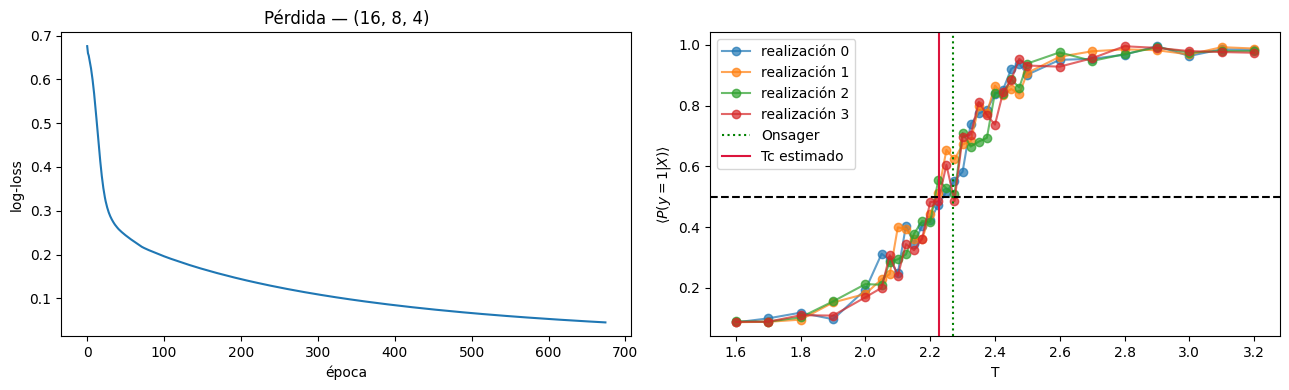

Arquitectura: (64,) | semilla: 42
iteraciones: 95   log-loss final: 0.0037
accuracy: {'train': 1.0, 'val': 0.975, 'test': 0.9675}
Tc = 2.3736 (std entre realizaciones = 0.0264) | Onsager = 2.2692 | error relativo = 4.60 %
pendiente en el cruce: 4.470 por unidad de T


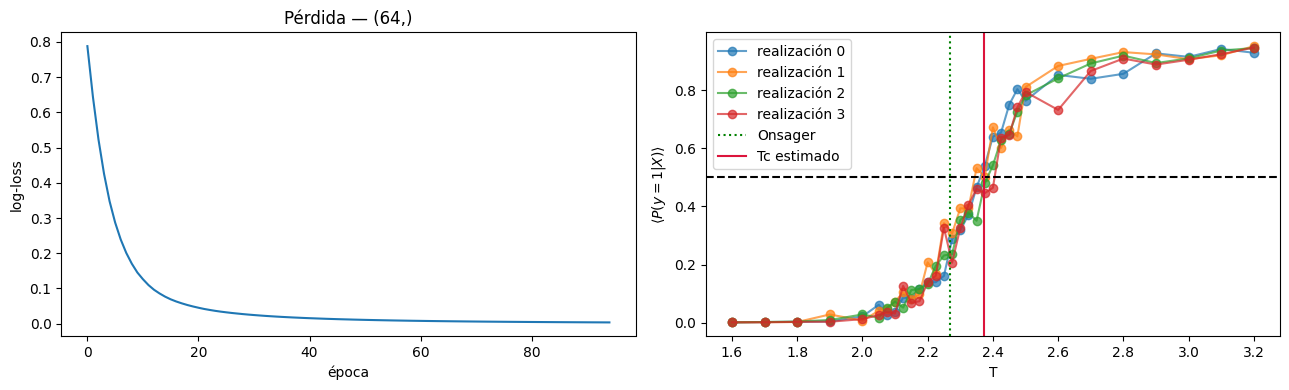

Arquitectura: (32, 16, 8) | semilla: 42
iteraciones: 80   log-loss final: 0.0019
accuracy: {'train': 1.0, 'val': 0.98, 'test': 0.985}
Tc = 2.3652 (std entre realizaciones = 0.0131) | Onsager = 2.2692 | error relativo = 4.23 %
pendiente en el cruce: 4.562 por unidad de T


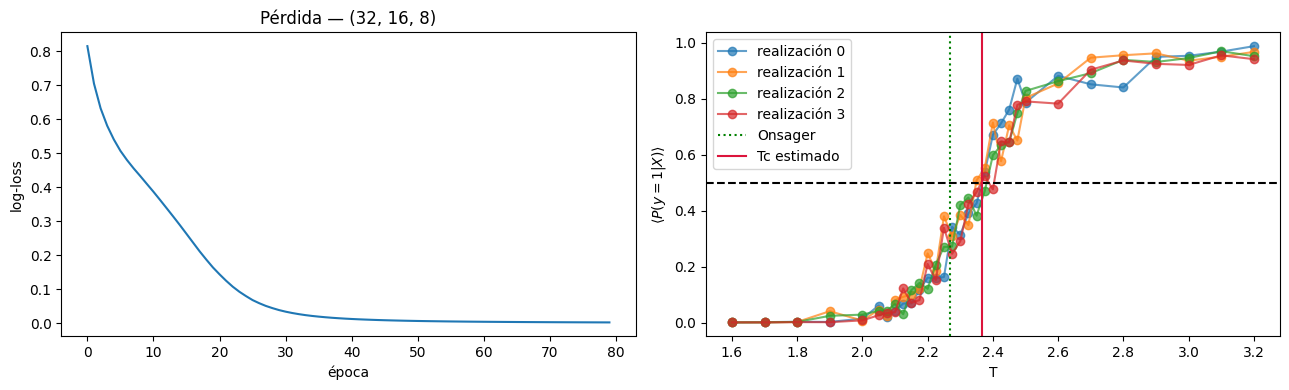

arquitectura     Tc  std entre realizaciones  pendiente en el cruce  accuracy test  error relativo [%]
  (16, 8, 4) 2.2259                   0.0110                 3.6835         0.9875              1.9070
       (64,) 2.3736                   0.0264                 4.4701         0.9675              4.6004
 (32, 16, 8) 2.3652                   0.0131                 4.5618         0.9850              4.2296


In [41]:
model_base, acc_base, info_base = entrenar_mlp((16, 8, 4), plots=True)    # referencia
model_64,   acc_64,   info_64   = entrenar_mlp((64,),      plots=True)
model_328,  acc_328,  info_328  = entrenar_mlp((32, 16, 8), plots=True)

tabla = pd.DataFrame({
    "arquitectura": ["(16, 8, 4)", "(64,)", "(32, 16, 8)"],
    "Tc": [i["Tc_est"] for i in (info_base, info_64, info_328)],
    "std entre realizaciones": [i["Tc_std"] for i in (info_base, info_64, info_328)],
    "pendiente en el cruce": [i["pendiente"] for i in (info_base, info_64, info_328)],
    "accuracy test": [a["test"] for a in (acc_base, acc_64, acc_328)],
})
tabla["error relativo [%]"] = 100 * (tabla["Tc"] - Tc_exacto).abs() / Tc_exacto
print(tabla.round(4).to_string(index=False))

### Hidden layers size = (32,16,8)

## 8.3 -  Reproducibilidad:
    Entrena con 5 semillas distintas (`random_state`) y reporta
   $T_c$ media ± desviación. ¿La dispersión por semilla es mayor o menor que la dispersión
   entre realizaciones?

In [42]:
semillas = [0, 1, 2, 3, 4]
Tc_sem, std_real = [], []
for s in semillas:
    _, _, info = entrenar_mlp((16, 8, 4), random_state=s, verbose=False)
    Tc_sem.append(info["Tc_est"])
    std_real.append(info["Tc_std"])
    print(f"semilla {s}: Tc = {info['Tc_est']:.4f} | std entre realizaciones = {info['Tc_std']:.4f}")

Tc_sem = np.array(Tc_sem)
print(f"\nTc entre semillas: {Tc_sem.mean():.4f} ± {Tc_sem.std(ddof=1):.4f}   (dispersión por semilla)")
print(f"Dispersión entre realizaciones (promedio sobre semillas): {np.mean(std_real):.4f}")

semilla 0: Tc = 2.3578 | std entre realizaciones = 0.0147
semilla 1: Tc = 2.3633 | std entre realizaciones = 0.0223
semilla 2: Tc = 2.3619 | std entre realizaciones = 0.0217
semilla 3: Tc = 2.2767 | std entre realizaciones = 0.0290
semilla 4: Tc = 2.3583 | std entre realizaciones = 0.0227

Tc entre semillas: 2.3436 ± 0.0375   (dispersión por semilla)
Dispersión entre realizaciones (promedio sobre semillas): 0.0221


## 8.4 - Definición alternativa:
Usa la *fracción de configuraciones clasificadas como fase 1*
   (`pred.mean()` por $T$) en vez de `prob_media`. ¿Obtienes el mismo $T_c$?

In [43]:
info_prob = estimar_Tc(model_base)                        # <P> medio (lo que ya hacías)
info_frac = estimar_Tc(model_base, usar_fraccion=True)    # fracción de configuraciones con pred = 1
print(f"Con prob. media:      Tc = {info_prob['Tc_est']:.4f} ± {info_prob['Tc_std']:.4f}")
print(f"Con fracción pred=1:  Tc = {info_frac['Tc_est']:.4f} ± {info_frac['Tc_std']:.4f}")
print(f"Diferencia: {info_frac['Tc_est'] - info_prob['Tc_est']:+.4f}")

Con prob. media:      Tc = 2.2259 ± 0.0110
Con fracción pred=1:  Tc = 2.2331 ± 0.0134
Diferencia: +0.0072


## 8.5 - Estandarización:
 Los espines ya están en $\{-1,+1\}$. ¿Ayuda un `StandardScaler`?
   ¿Por qué sí o por qué no en este problema?

In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

modelo_std = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(16, 8, 4), activation="relu", solver="adam",
                  learning_rate_init=0.001, max_iter=1000, random_state=RNG))
modelo_std.fit(X_train, y_train)
info_std = estimar_Tc(modelo_std)

print("accuracy val/test con StandardScaler:", round(modelo_std.score(X_val, y_val), 4), round(modelo_std.score(X_test, y_test), 4))
print(f"Tc sin escalar:  {info_base['Tc_est']:.4f} ± {info_base['Tc_std']:.4f}")
print(f"Tc con scaler:   {info_std['Tc_est']:.4f} ± {info_std['Tc_std']:.4f}")
print("Media y desviación de las características (entrenamiento):",
      round(X_train.mean(), 3), round(X_train.std(), 3))

accuracy val/test con StandardScaler: 0.9875 0.99
Tc sin escalar:  2.2259 ± 0.0110
Tc con scaler:   2.2076 ± 0.0083
Media y desviación de las características (entrenamiento): 0.051 0.999


## 9. Reto  — Escalamiento con el tamaño del sistema

Con el programa de ising generar varias datos para diferentes tipo de redes L=10x10, L=15x15, L=20x20, L=25x25, L=30x30

1. Construye un conjunto de entrenamiento.
2. Entrena un nuevo `MLPClassifier`, repite los Ejercicios 4–5 y obtén $T_c(L=20)$.
3. Compara todas las $T_c$ ¿La estimación se acerca a Onsager al crecer $L$?
   Relaciónalo con el *finite-size scaling*.

In [45]:
# Reto (opcional): esqueleto para L = 20 .... NOTA: esta parte dice que es opcional, entonces no se presentara en la tarea, solo se va a dejar hasta el 8.5 !
